In [2]:
#hide
!pip install -Uqq fastbook
import fastbook
fastbook.setup_book()

In [3]:
#hide
from fastbook import *
from fastai.vision.widgets import *

In [4]:
search_images_ddg

<function fastbook.search_images_ddg(term, max_images=200)>

In [5]:
from ddgs import DDGS as ddgs


In [6]:
from ddgs import DDGS
from fastai.vision.all import *

search = DDGS()
img = list(search.images("damaged cars", max_results=10))
urls = [item["image"] for item in img]

from IPython.display import Image, display,HTML
# display(Image(url=img[2]["image"]))
display(HTML("".join(
    f'<img src="{item["image"]}" width="150" style="margin:5px;">'
    for item in img[:5]
)))

path = Path("bears")
path.mkdir(exist_ok=True)

download_images(path, urls=urls)

In [7]:
# fns = get_image_files(path)
# im = PILImage.create(fns[2])
# im.to_thumb(64, 64)

In [8]:
fns = get_image_files(path)
print(len(fns))

69


In [9]:
dest ='bears/2026b0d6-79ea-4952-a5fb-a1cd4a4221e9.jpeg'
from PIL import Image
im = Image.open(dest)
im.thumbnail((128,128))

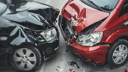

In [10]:
display(im)

In [11]:
bear_types = 'grizzly_bear','black_bear','bearlike_photo'
path = Path('bear')

In [12]:
if not path.exists():
    path.mkdir()
    for o in bear_types:
        dest = (path/o)
        dest.mkdir(exist_ok=True)
        img = list(search.images(o, max_results=150))
        urls = [item["image"] for item in img] 
        download_images(dest, urls=urls)

In [13]:
fns = get_image_files(path)
print(len(fns))
print(fns[3])

69
bear\bearlike_photo\37f29e90-945a-442e-a108-4fe80feab7cc.jpg


In [14]:
failed = L(
    f for f in fns
    if not verify_image(f)
)

print("Invalid images:", len(failed))
failed.map(Path.unlink)
print("Remaining images:", len(get_image_files(path)))

Invalid images: 0
Remaining images: 69


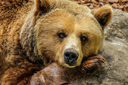

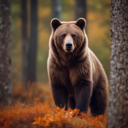

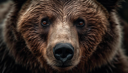

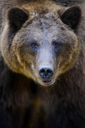

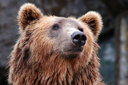

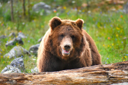

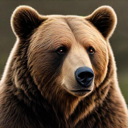

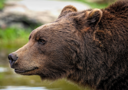

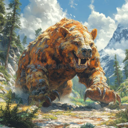

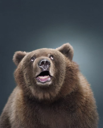

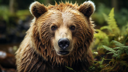

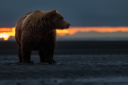

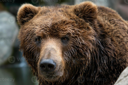

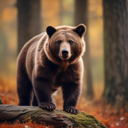

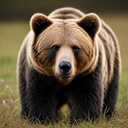

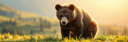

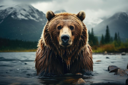

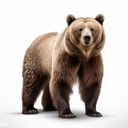

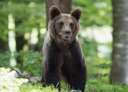

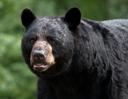

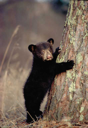

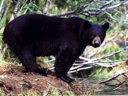

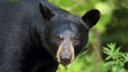

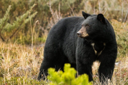

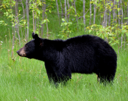

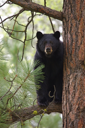

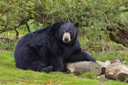

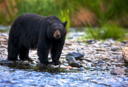

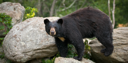

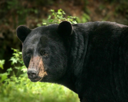

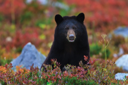

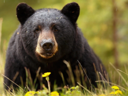

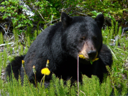

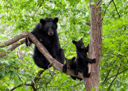

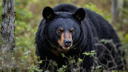

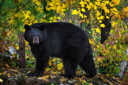

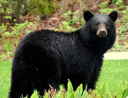

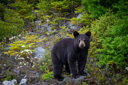

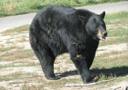

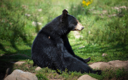

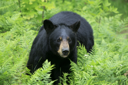

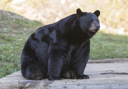

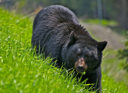

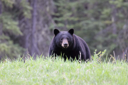

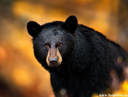

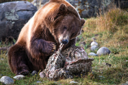

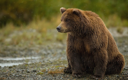

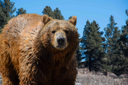

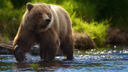

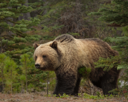

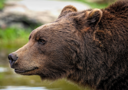

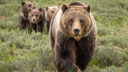

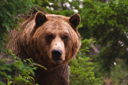

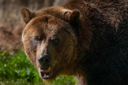

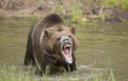

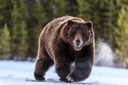

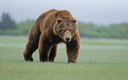

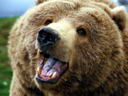

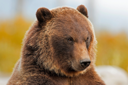

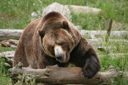

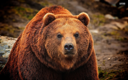

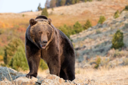

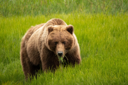

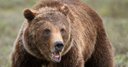

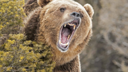

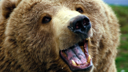

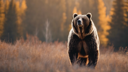

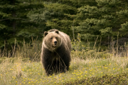

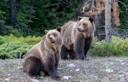

In [15]:
fns = get_image_files(path)
for f in fns:
    im = PILImage.create(f)
    display(im.to_thumb(128, 128))

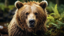

In [16]:
im = PILImage.create(fns[10])
display(im.to_thumb(64, 64))

In [17]:
print(len(fns))
print(fns[1])

69
bear\bearlike_photo\18d6ae89-5200-406c-80b7-66358dadde02.jpg


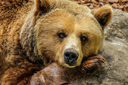

In [18]:
dest =r'bear\bearlike_photo\172cb240-54e2-42ab-84f6-e305d5974681.jpg'
from PIL import Image
im = Image.open(dest)
im.thumbnail((128,128))
display(im)

In [19]:
dblock=DataBlock(blocks=(ImageBlock,CategoryBlock),
              get_y=parent_label,
               splitter=RandomSplitter(valid_pct=.2,seed=23),
               item_tfms=Resize(128),
               get_items=get_image_files
                )

In [20]:
dls=dblock.dataloaders(path,bs=16,device='cuda')
dls.train.drop_last=False

In [21]:
print("Training images:", len(dls.train_ds))
print("Validation images:", len(dls.valid_ds))

images, labels = dls.one_batch()

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

Training images: 56
Validation images: 13
Images shape: torch.Size([16, 3, 128, 128])
Labels shape: torch.Size([16])


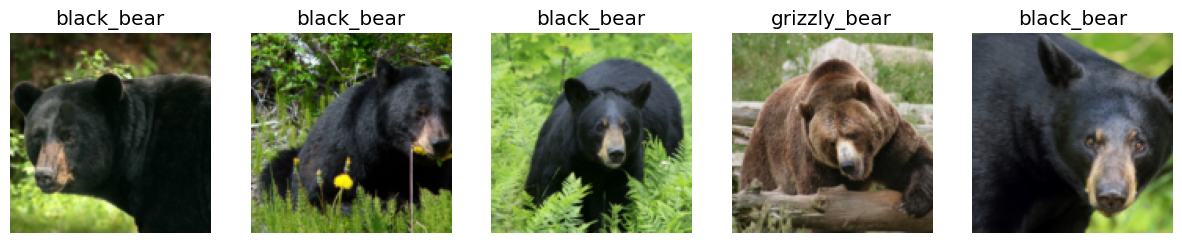

In [22]:
dls.train.show_batch(max_n=5, nrows=1)

In [23]:
fns = get_image_files(path)

In [24]:
print("Total images:", len(fns))
print("Training images:", len(dls.train_ds))
print("Validation images:", len(dls.valid_ds))
print("Training batches:", len(dls.train))
print("Training batches:", len(dls.valid))

Total images: 69
Training images: 56
Validation images: 13
Training batches: 4
Training batches: 1


In [25]:
print("Drop last batch:", dls.train.drop_last)

for i, (images, labels) in enumerate(dls.train):
    print(f"Batch {i+1}: {len(images)} images")

Drop last batch: False
Batch 1: 16 images
Batch 2: 16 images
Batch 3: 16 images
Batch 4: 8 images


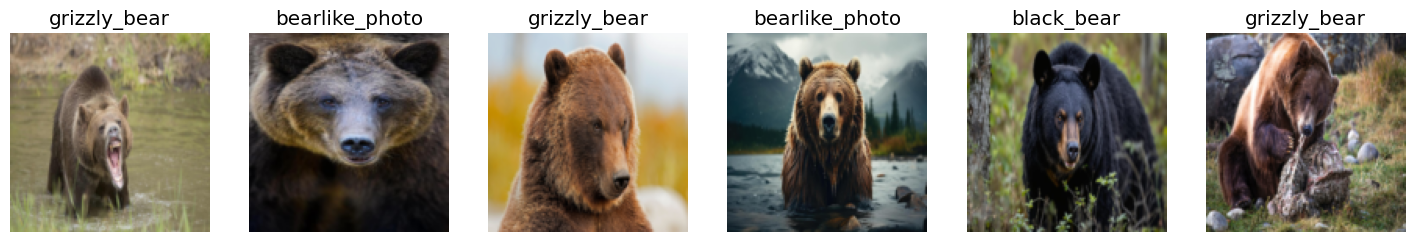

In [26]:
bears = dblock.new(item_tfms=Resize(128, ResizeMethod.Squish))
dls = bears.dataloaders(path)
dls.valid.show_batch(max_n=6, nrows=1)

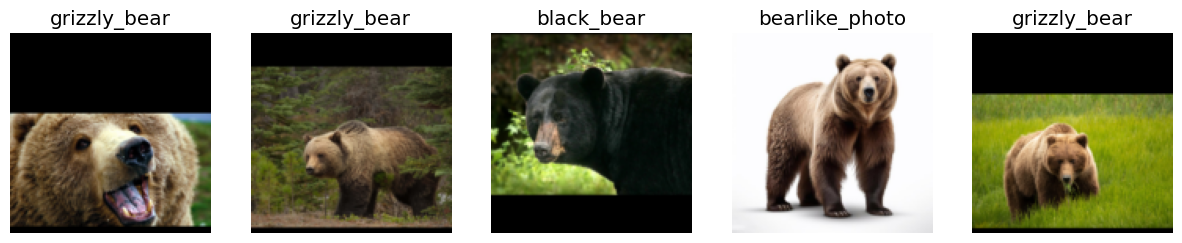

In [27]:
bears = dblock.new(item_tfms=Resize(128, ResizeMethod.Pad, pad_mode='zeros'))
dls = bears.dataloaders(path,bs=8)
dls.train.show_batch(max_n=5, nrows=1)

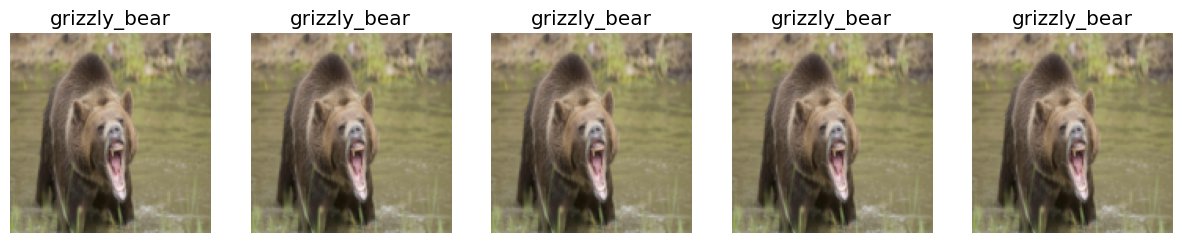

In [28]:
bears = dblock.new(item_tfms=RandomResizedCrop(128, min_scale=0.4))
dls = bears.dataloaders(path,bs=8)
dls.valid.show_batch(max_n=5, nrows=1, unique=True)

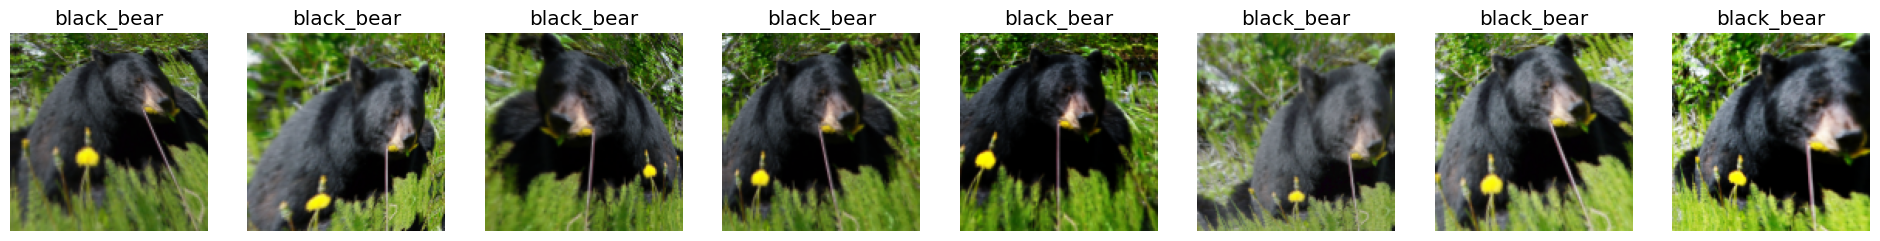

In [29]:
bears =dblock.new(item_tfms=Resize(128), batch_tfms=aug_transforms(mult=2))
dls = bears.dataloaders(path,bs=8)
dls.train.show_batch(max_n=8, nrows=1, unique=True)

In [30]:
print("Training images:", len(dls.train_ds))
print("Validation images:", len(dls.valid_ds))

print("Training batches:", len(dls.train))
print("Validation batches:", len(dls.valid))
for i, (images, labels) in enumerate(dls.train):
    print(f"Batch {i+1}: {len(images)} images")

Training images: 56
Validation images: 13
Training batches: 7
Validation batches: 2
Batch 1: 8 images
Batch 2: 8 images
Batch 3: 8 images
Batch 4: 8 images
Batch 5: 8 images
Batch 6: 8 images
Batch 7: 8 images


In [31]:
bears = dblock.new(
    item_tfms=RandomResizedCrop(224, min_scale=0.5),
    batch_tfms=aug_transforms(mult=2))
dls = bears.dataloaders(path,bs=16)
dls.train.drop_last=False

In [32]:
for i, (images, labels) in enumerate(dls.train):
    print(f"Batch {i+1}: {len(images)} images")
print("Drop last batch:", dls.train.drop_last)    

Batch 1: 16 images
Batch 2: 16 images
Batch 3: 16 images
Batch 4: 8 images
Drop last batch: False


In [33]:
learn = vision_learner(dls, resnet18, metrics=error_rate)
learn.fine_tune(4)

epoch,train_loss,valid_loss,error_rate,time
0,2.046558,2.007035,0.615385,00:08


epoch,train_loss,valid_loss,error_rate,time
0,1.151983,1.111563,0.461538,00:07
1,0.799090,0.407402,0.307692,00:08
2,0.808886,0.312179,0.153846,00:07
3,0.691185,0.249749,0.076923,00:07


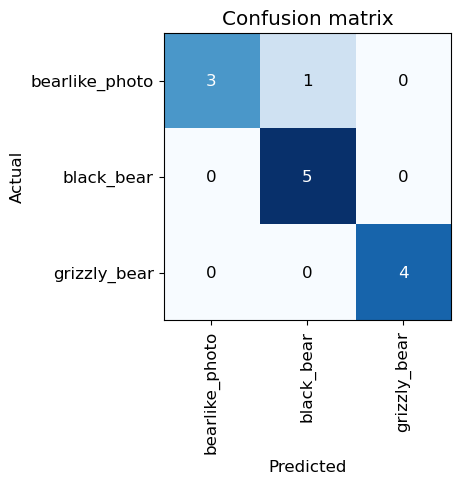

In [34]:
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()

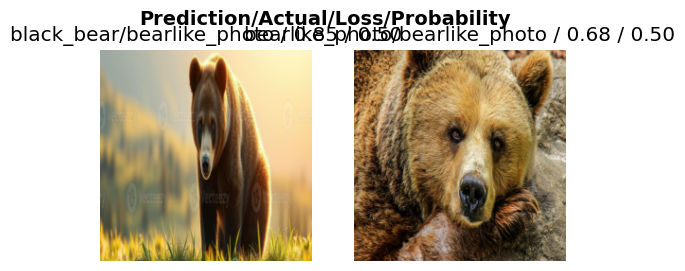

In [35]:
interp.plot_top_losses(2, nrows=1)

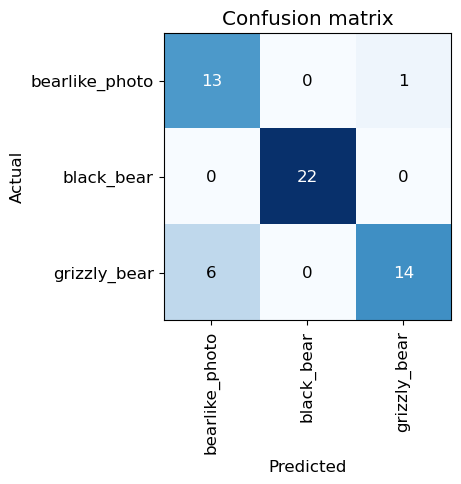

In [36]:
interp = ClassificationInterpretation.from_learner(learn,dl=dls.train)
interp.plot_confusion_matrix()

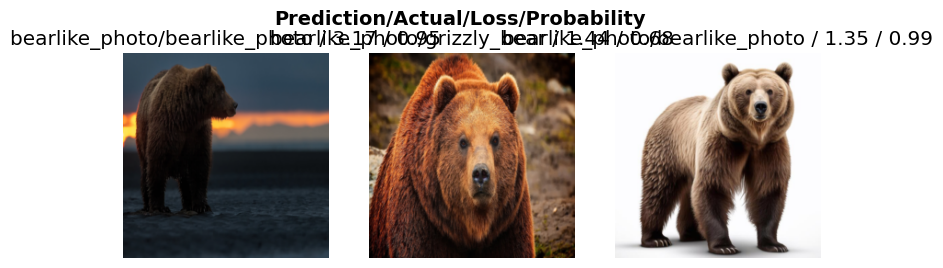

In [37]:
interp.plot_top_losses(3, nrows=1)

In [38]:
cleaner = ImageClassifierCleaner(learn)
cleaner

In [39]:
for idx in cleaner.delete(): cleaner.fns[idx].unlink()
for idx,cat in cleaner.change(): shutil.move(str(cleaner.fns[idx]), path/cat)

In [40]:
import huggingface_hub
print(huggingface_hub.__version__)

2.2.0


In [42]:
learn.export()

In [43]:
path = Path()
path.ls(file_exts='.pkl')

[Path('export.pkl')]

In [46]:
learn.predict(r"bears\09be4373-d0a8-4d1f-b4fd-a88840679f8e.jpg")

('bearlike_photo', tensor(0), tensor([0.8031, 0.0258, 0.1711]))

In [56]:
learn.predict(r"bear\grizzly_bear\1ec910c4-4a84-4ce7-bf70-0fea59521107.png")

('bearlike_photo', tensor(0), tensor([0.6471, 0.0596, 0.2933]))

In [56]:
learn.predict(r"bear\grizzly_bear\1ec910c4-4a84-4ce7-bf70-0fea59521107.png")

('bearlike_photo', tensor(0), tensor([0.6471, 0.0596, 0.2933]))

In [59]:
learn.dls.vocab

['bearlike_photo', 'black_bear', 'grizzly_bear']

In [101]:
category=('bearlike_photo', 'black_bear', 'grizzly_bear')
def classify_image(img):
    pred,idx,probs=learn.predict(img)
    return dict(zip(category,map(float,probs)))

In [102]:
classify_image(r"bear\grizzly_bear\1ec910c4-4a84-4ce7-bf70-0fea59521107.png")

{'bearlike_photo': 0.6470560431480408,
 'black_bear': 0.05960467457771301,
 'grizzly_bear': 0.2933392822742462}

In [95]:
fns = get_image_files(path/'bear')


In [97]:
import gradio as gr

In [103]:
image = gr.Image(
    type="pil",
    label="Upload a bear image"
)
label = gr.Label(num_top_classes=3)

examples = [[str(f)] for f in fns[:5]]
imgf=gr.Interface(fn=classify_image,inputs=image,outputs=label,examples=examples)

In [104]:

imgf.launch()

ERROR:    [Errno 10048] error while attempting to bind on address ('127.0.0.1', 7860): [winerror 10048] only one usage of each socket address (protocol/network address/port) is normally permitted


* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


Traceback (most recent call last):
  File "C:\Users\ayush\anaconda3\Lib\site-packages\gradio\queueing.py", line 848, in process_events
    response = await route_utils.call_process_api(
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
    )
    ^
  File "C:\Users\ayush\anaconda3\Lib\site-packages\gradio\route_utils.py", line 417, in call_process_api
    output = await app.get_blocks().process_api(
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<12 lines>...
    )
    ^
  File "C:\Users\ayush\anaconda3\Lib\site-packages\gradio\blocks.py", line 2698, in process_api
    result = await self.call_function(
             ^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<9 lines>...
    )
    ^
  File "C:\Users\ayush\anaconda3\Lib\site-packages\gradio\blocks.py", line 1963, in call_function
    prediction = await anyio.to_thread.run_sync(  # type: ignore
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
        fn, *processed_input, limiter=self.limiter
        ^^

In [108]:
from nbdev import nbdev_export

nbdev_export()

Exception: `nbdev-export` must be called from a directory within a nbdev project.

In [110]:
!jupyter nbconvert --to script dl2.ipynb

[NbConvertApp] Converting notebook dl2.ipynb to script
[NbConvertApp] Writing 7949 bytes to dl2.py


In [111]:
import os

print(os.listdir())

['.ipynb_checkpoints', '01_intro.ipynb', '02_production.ipynb', 'a.py', 'bear', 'bears', 'bird.jpg', 'bird_forest', 'dl2.ipynb', 'dl2.py', 'export.pkl', 'feismo.com-radek-osmulski-meta-learning-how-to-learn-deep-learning-and-thrive-in-the-digi-pr_7b3a3c97f67dc4c1021688aa8a26cce3.pdf', 'forest.jpg', 'is-it-a-bird-creating-a-model-from-your-own-data.ipynb', 'wood-flight-bird-326900.jpg']


In [88]:
# %pip install gradio

In [60]:
#hide_output
btn_upload = widgets.FileUpload()
btn_upload

FileUpload(value={}, description='Upload')

In [67]:
btn_upload = SimpleNamespace(data = [r"bear\bearlike_photo\de36ce58-da2f-4d43-9e14-1fb1c80294d1.jpg"])

In [68]:
img = PILImage.create(btn_upload.data[-1])

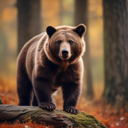

In [69]:
display(img.to_thumb(128, 128))

In [70]:
out_pl = widgets.Output()
out_pl.clear_output()
with out_pl: display(img.to_thumb(128,128))
out_pl

Output()

In [72]:
pred,pred_idx,probs = learn.predict(img)
#hide_output
lbl_pred = widgets.Label()
lbl_pred.value = f'Prediction: {pred}; Probability: {probs[pred_idx]:.04f}'
lbl_pred

Label(value='Prediction: bearlike_photo; Probability: 0.9943')

In [74]:
#hide_output
btn_run = widgets.Button(description='Classify')
btn_run
def on_click_classify(change):
    img = PILImage.create(btn_upload.data[-1])
    out_pl.clear_output()
    with out_pl: display(img.to_thumb(128,128))
    pred,pred_idx,probs = learn_inf.predict(img)
    lbl_pred.value = f'Prediction: {pred}; Probability: {probs[pred_idx]:.04f}'

btn_run.on_click(on_click_classify)

In [75]:
btn_upload = widgets.FileUpload()

In [76]:
#hide_output
VBox([widgets.Label('Select your bear!'), 
      btn_upload, btn_run, out_pl, lbl_pred])

In [2]:
import os

print(os.listdir())
print(os.getcwd())

['requirements.txt', 'README.md', 'app.ipynb', 'app1.py', 'style.css', 'app.py', '.git', '.gradio', '.gitattributes', 'index.html']
/home/ayush_coder/git/a
